# Plasma PIC Simulations

One of the techniques used in plasma simulations is something called particle-in-cell, or PIC. One of the problems in any particle simulation, especially those that begin with first-principles, is that we can very quickly become overwhelmed with the number of calculations involved. The number of particles that allows us to look at interesting effects very quickly becomes too much, even for modern computers.

To solve this, we need to move to techniques that allow us to reduce the computational load. PIC is one of these techniques. This notebook will go over a toy example in 1D, just to show the basics of the technique. The example involves two electron beams traveling in opposite directions in an unmagnetised uniform bath of ions.

### Particle in cell method

In this example, we will have N electrons that we will be tracking. We will want to track two parameters of each particle:

* $r_i$  -  the position
* $v_i$  -  the velocity

The only interaction that we will be looking at is the electric field effects. This means that each electron will be feeling an acceleration due to the electric field being generated by all of the other electrons in the simulation. The equations of motion for the electrons are

* $\frac{dr_i}{dt} = v_i$
* $\frac{dv_i}{dt} = a_i = -E(r_i)$

To calculate the acceleration, we need the electric field which is proportional to the number density **n** of electrons. The electric field **E** is defined as the negative gradient of the electric potential $\phi$, which is given by Poisson's equation sourced by the density

* $E(x) = -\frac{d\phi}{dx}$
* $\frac{d^2 \phi}{dx^2} = n - n_O$

where $n_O$ is the average density.

The Particle-In-Cell (PIC) Method computes the density and subsequently the potential and electric field on a mesh. Hence it is called a particle-mesh method. The electric field is then extrapolated onto the location of the particles in order to advance them.

### Density calculation

The density is obtained by binning the particles onto the mesh gridpoints. Call the separation distance between mesh points Δx. A particle with position $r_i$ will lie between a pair of coordinates $x_j$ and $x_{j+1}$ on the mesh. Then, the densities $n_j$ and $n_{j+1}$ at these two points gain a contribution:

* $n_j += \frac{x_{j+1} - r_i}{\Delta x}$
* $n_{j+1} += \frac{r_i - x_j}{\Delta x}$

After collecting contribution from all particles, the density has to be properly normalized so that the average density is the specified $n_O$.

### Potential calculation

Knowing the density $n_j$ on the mesh grid points, we now seek the potential $\phi_j$ at these points. The second-derivative operator (called the ‘Laplacian’) in Poisson’s equation can be approximated on the mesh with a finite-different formula:

$\frac{d^2 \phi(x_j)}{dx^2} \approx \frac{\phi_{j-1} - 2\phi_j + \phi_{j+1}}{(\Delta x)^2}$

If all the values for $n_j$ are arranged into a column vector, and similarly for $\phi_j$, then the equation can be written as a system of linear equations in matrix form:

$\frac{1}{(\Delta x)^2} \left[ \begin{array}{ccccc}
-2 & 1 & 0 & \cdot\cdot\cdot & 1 \\
1 & -2 & 1 & \cdot\cdot\cdot & 0 \\
\cdot \\
\cdot \\
\cdot \\
1 & \cdot\cdot\cdot & 0 & 1 & -2
\end{array} \right] \left[ \begin{array}{c}
\phi_1 \\
\phi_2 \\
\cdot \\
\cdot \\
\cdot \\
\phi_m
\end{array} \right] = \left[ \begin{array}{c}
n_1 \\
n_2 \\
\cdot \\
\cdot \\
\cdot \\
n_m
\end{array} \right] - n_O$

The matrix represents the Laplacian operator and is sparse and tridiagonal. We have assumed periodic boundary conditions, i.e., the endpoints of the mesh wrap around to each other, which add the ‘1’s in the top-right and bottom-left corners of the matrix. This matrix equation can be efficiently numerically inverted and solved by using pre-built linear algebra packages such as the Python Scipy package’s “spsolve” function.

### Electric field calculation

Given that we have solved for $\phi_j$ on the mesh, we can next solve for the electric field $E_j$ by discretizing the first-derivative operator (called the ‘gradient’):

$\frac{d\phi(x_j)}{dx} \approx \frac{\phi_{j+1} - \phi_{j-1}}{2 \Delta x}$

Again we can write out the system of equations in matrix form:

$\left[ \begin{array}{c}
E_1 \\
E_2 \\
\cdot \\
\cdot \\
\cdot \\
E_m
\end{array} \right] = - \frac{1}{2 \Delta x} \left[ \begin{array}{ccccc}
0 & 1 & 0 & \cdot\cdot\cdot & -1 \\
-1 & 0 & 1 & \cdot\cdot\cdot & 0 \\
\cdot \\
\cdot \\
\cdot \\
1 & \cdot\cdot\cdot & 0 & -1 & 0 \end{array} \right] \left[ \begin{array}{c}
\phi_1 \\
\phi_2 \\
\cdot \\
\cdot \\
\cdot \\
\phi_m \end{array} \right]$

The system is simpler this time. There is no need to invert a matrix. The electric field is directly obtained by applying the matrix multiplication.

### Acceleration calculation

So far we have gone from particles to mesh values of density to potential to electric field. To complete the loop, we need the electric field at the location of the particles. Fortunately, this can now be done with interpolation from the 2 nearest gridpoints $x_j$ and $x_{j+1}$. For particle i, the electric field $E_i$ is:

$E_i = \frac{x_{j+1} - r_i}{\Delta x} E_{j+1} + \frac{r_i - x_j}{\Delta x} E_j$

using similar weights as when be binned to get density.

### Time integration

We are almost done. We will loop over timesteps and evolve the electrons using a leap-frog scheme (‘kick-drift-kick’). For each timestep &\Delta t&, each particle receives a half-step ‘kick’:

$v_i = v_i + \frac{\Delta t}{2} \times a_i$

followed by a full-step ‘drift’:

$r_i = r_i + \Delta t \times v_i$

followed by another half-step ‘kick’.

### Initial conditions

The only thing left to do is specify the initial conditions (positions and velocities at time t=0) of the electrons in the simulation. In the code, we implement the example that we have a uniform beam traveling to the right, and another one superimposed, traveling left. Particle positions are drawn from a random uniform distribution. Velocities are drawn from a Gaussian centered about the beam velocity (one positive, one negative). Small initial perturbations in the form of a cosine function are added to the velocity distribution.

In [1]:
# Initial imports of needed Python modules
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve

In [2]:
# The function that calculates the acceleration of the particles
def getAcc( pos, Nx, boxsize, n0, Gmtx, Lmtx ):
    """
    Calculate the acceleration on each particle due to electric field
    pos      is an Nx1 matrix of particle positions
    Nx       is the number of mesh cells
    boxsize  is the domain [0,boxsize]
    n0       is the electron number density
    Gmtx     is an Nx x Nx matrix for calculating the gradient on the grid
    Lmtx     is an Nx x Nx matrix for calculating the laplacian on the grid
    a        is an Nx1 matrix of accelerations
    """
    # Calculate Electron Number Density on the Mesh by 
    # placing particles into the 2 nearest bins (j & j+1, with proper weights)
    # and normalizing
    N          = pos.shape[0]
    dx         = boxsize / Nx
    j          = np.floor(pos/dx).astype(int)
    jp1        = j+1
    weight_j   = ( jp1*dx - pos  )/dx
    weight_jp1 = ( pos    - j*dx )/dx
    jp1        = np.mod(jp1, Nx)   # periodic BC
    n  = np.bincount(j[:,0],   weights=weight_j[:,0],   minlength=Nx);
    n += np.bincount(jp1[:,0], weights=weight_jp1[:,0], minlength=Nx);
    n *= n0 * boxsize / N / dx 

    # Solve Poisson's Equation: laplacian(phi) = n-n0
    phi_grid = spsolve(Lmtx, n-n0, permc_spec="MMD_AT_PLUS_A")
    
    # Apply Derivative to get the Electric field
    E_grid = - Gmtx @ phi_grid

    # Interpolate grid value onto particle locations
    E = weight_j * E_grid[j] + weight_jp1 * E_grid[jp1]

    a = -E

    return a

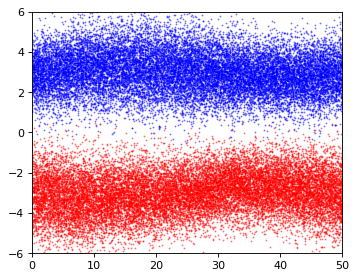

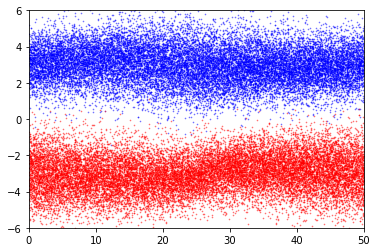

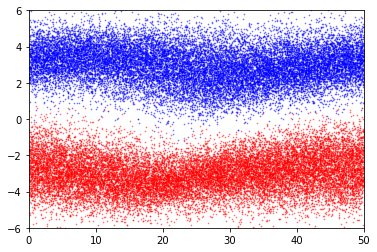

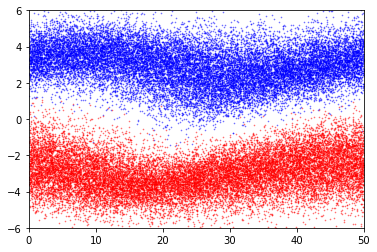

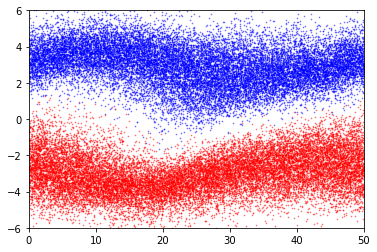

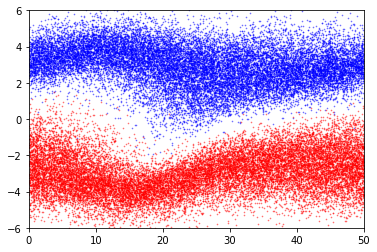

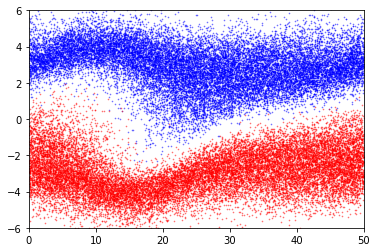

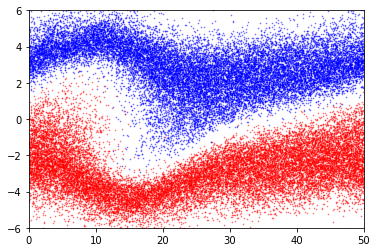

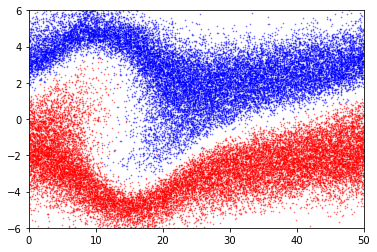

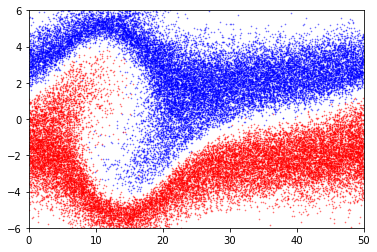

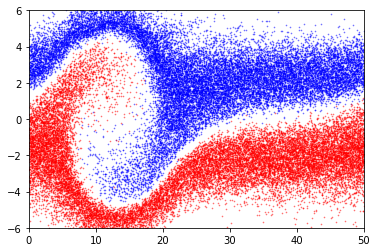

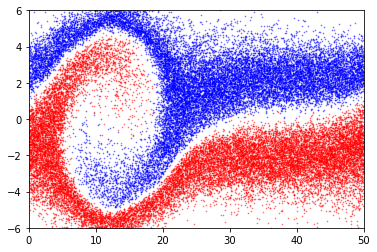

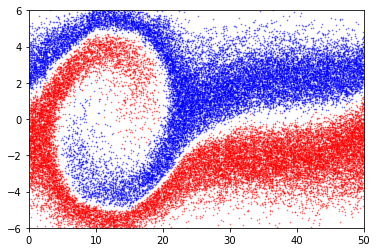

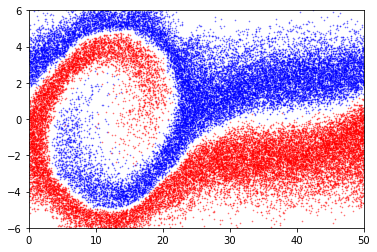

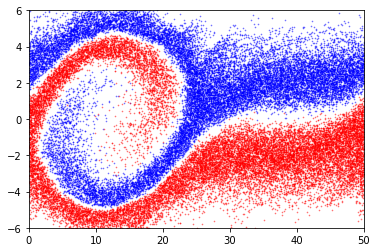

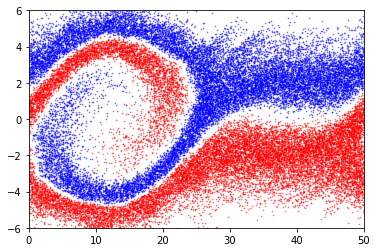

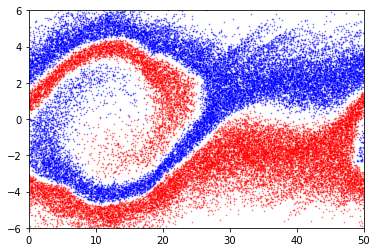

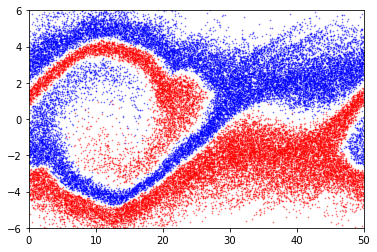

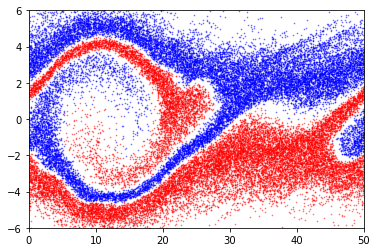

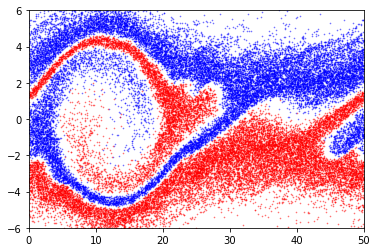

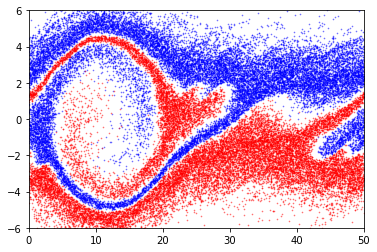

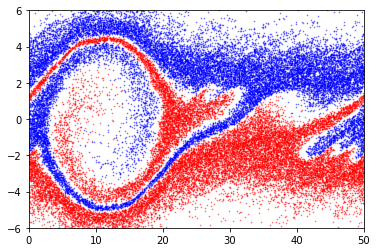

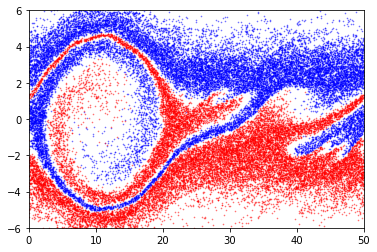

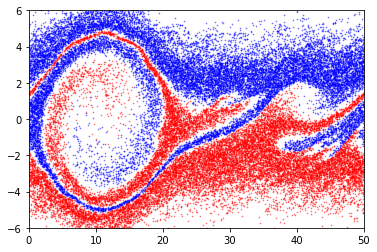

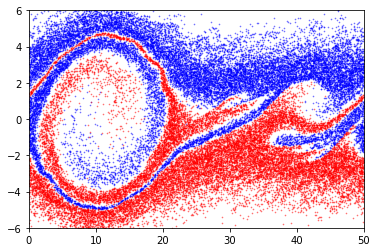

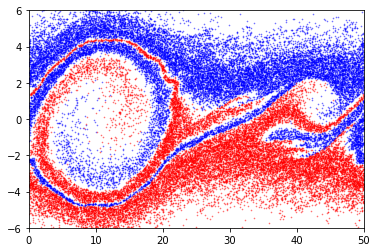

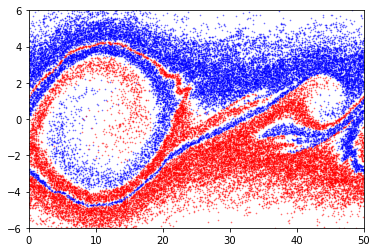

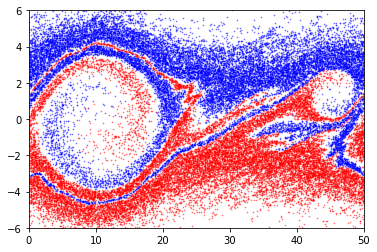

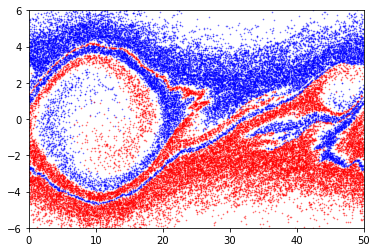

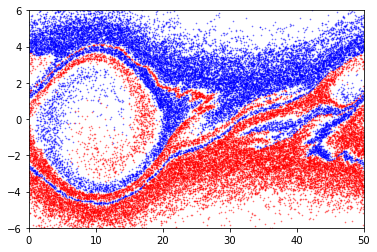

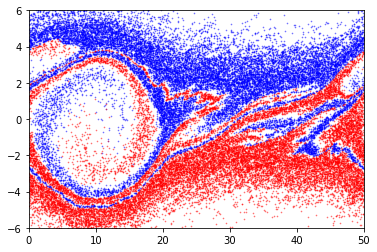

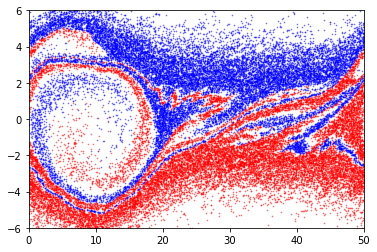

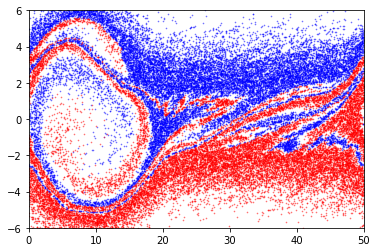

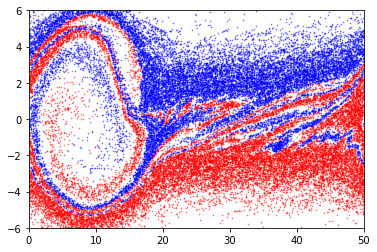

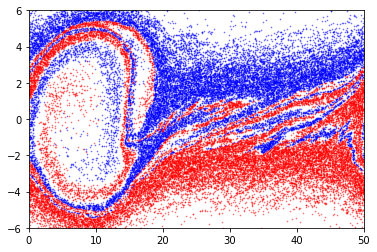

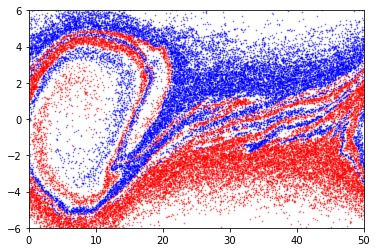

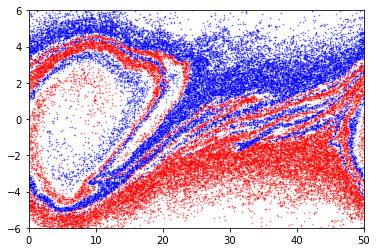

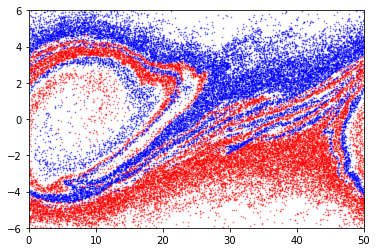

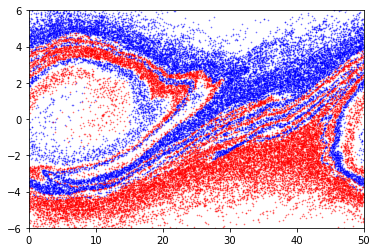

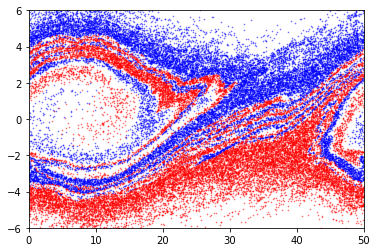

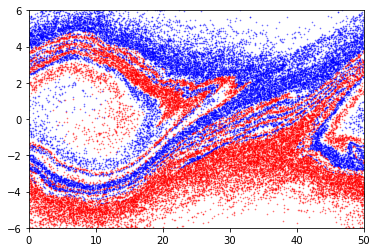

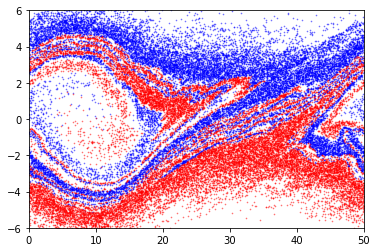

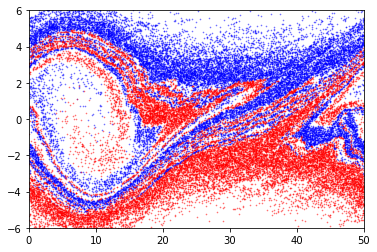

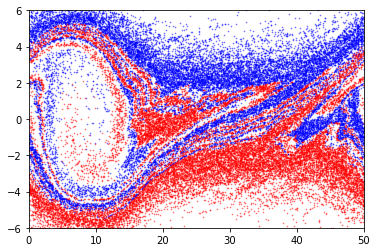

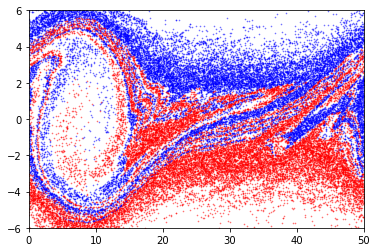

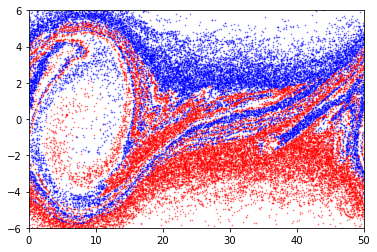

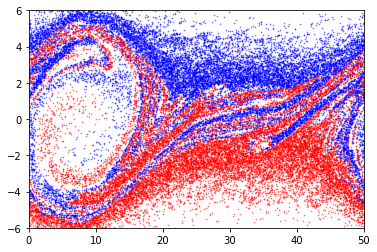

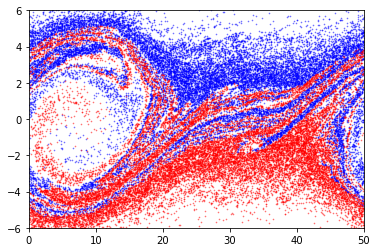

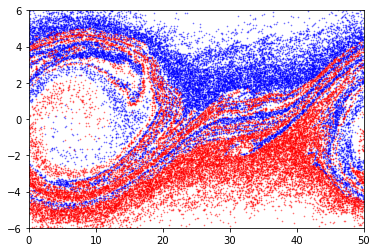

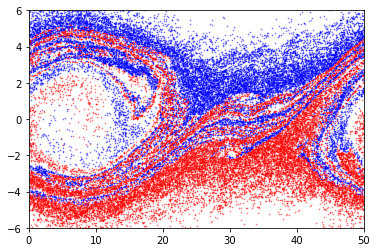

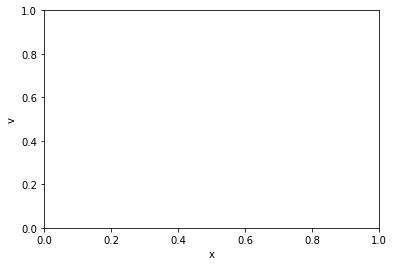

In [3]:
""" Plasma PIC simulation """

# Simulation parameters
N         = 40000   # Number of particles
Nx        = 400     # Number of mesh cells
t         = 0       # current time of the simulation
tEnd      = 50      # time at which simulation ends
dt        = 1       # timestep
boxsize   = 50      # periodic domain [0,boxsize]
n0        = 1       # electron number density
vb        = 3       # beam velocity
vth       = 1       # beam width
A         = 0.1     # perturbation
plotRealTime = True # switch on for plotting as the simulation goes along

# Generate Initial Conditions
np.random.seed(42)            # set the random number generator seed
# construct 2 opposite-moving Guassian beams
pos  = np.random.rand(N,1) * boxsize  
vel  = vth * np.random.randn(N,1) + vb
Nh = int(N/2)
vel[Nh:] *= -1
# add perturbation
vel *= (1 + A*np.sin(2*np.pi*pos/boxsize))

# Construct matrix G to computer Gradient  (1st derivative)
dx = boxsize/Nx
e = np.ones(Nx)
diags = np.array([-1,1])
vals  = np.vstack((-e,e))
Gmtx = sp.spdiags(vals, diags, Nx, Nx);
Gmtx = sp.lil_matrix(Gmtx)
Gmtx[0,Nx-1] = -1
Gmtx[Nx-1,0] = 1
Gmtx /= (2*dx)
Gmtx = sp.csr_matrix(Gmtx)

# Construct matrix L to computer Laplacian (2nd derivative)
diags = np.array([-1,0,1])
vals  = np.vstack((e,-2*e,e))
Lmtx = sp.spdiags(vals, diags, Nx, Nx);
Lmtx = sp.lil_matrix(Lmtx)
Lmtx[0,Nx-1] = 1
Lmtx[Nx-1,0] = 1
Lmtx /= dx**2
Lmtx = sp.csr_matrix(Lmtx)

# calculate initial gravitational accelerations
acc = getAcc( pos, Nx, boxsize, n0, Gmtx, Lmtx )

# number of timesteps
Nt = int(np.ceil(tEnd/dt))

# prep figure
fig = plt.figure(figsize=(5,4), dpi=80)

# Simulation Main Loop
for i in range(Nt):
    # (1/2) kick
    vel += acc * dt/2.0

    # drift (and apply periodic boundary conditions)
    pos += vel * dt
    pos = np.mod(pos, boxsize)

    # update accelerations
    acc = getAcc( pos, Nx, boxsize, n0, Gmtx, Lmtx )

    # (1/2) kick
    vel += acc * dt/2.0

    # update time
    t += dt

    # plot in real time - color 1/2 particles blue, other half red
    if plotRealTime or (i == Nt-1):
        plt.cla()
        plt.scatter(pos[0:Nh],vel[0:Nh],s=.4,color='blue', alpha=0.5)
        plt.scatter(pos[Nh:], vel[Nh:], s=.4,color='red',  alpha=0.5)
        plt.axis([0,boxsize,-6,6])

        plt.pause(0.001)


# Save figure
plt.xlabel('x')
plt.ylabel('v')
plt.savefig('pic.png',dpi=240)
plt.show()